In [188]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

In [189]:
def newton_divided_difference(x_values, y_values):
    """
    Compute the interpolating polynomial using Newton's Divided Difference method.

    Parameters:
        x_values (list or array): x-coordinates of data points
        y_values (list or array): y-coordinates of data points

    Returns:
        polynomial (sympy expression): Interpolating polynomial
    """
    x = sp.Symbol('x')
    n = len(x_values)

    # Create divided difference table
    divided_diff = np.zeros((n, n), dtype=float)
    divided_diff[:, 0] = y_values

    for j in range(1, n):
        for i in range(n - j):
            divided_diff[i, j] = (
                divided_diff[i + 1, j - 1] - divided_diff[i, j - 1]
            ) / (x_values[i + j] - x_values[i])

    # Construct Newton polynomial
    polynomial = divided_diff[0, 0]
    term = 1

    for i in range(1, n):
        term *= (x - x_values[i - 1])
        polynomial += divided_diff[0, i] * term

    return sp.simplify(polynomial)

In [190]:
def plot_newton_divided_difference(x_values, y_values, polynomial, x_interp=None):
    """
    Plot the Newton interpolating polynomial, data points,
    and an interpolated value.

    Parameters:
        x_values (list or array): x-coordinates of data points
        y_values (list or array): y-coordinates of data points
        polynomial (sympy expression): Interpolating polynomial
        x_interp (float/optional): x-value at which to interpolate
    """
    x = sp.Symbol('x')
    f_lambdified = sp.lambdify(x, polynomial, 'numpy')

    x_plot = np.linspace(min(x_values) - 1, max(x_values) + 1, 500)
    y_plot = f_lambdified(x_plot)

    plt.plot(x_plot, y_plot, label="Newton Polynomial", color='blue')
    plt.scatter(x_values, y_values, color='red', label='Data Points', zorder=3)

    y_interp = None

    if x_interp is not None:
        y_interp = f_lambdified(x_interp)
        plt.scatter(
            [x_interp], [y_interp],
            color='green', marker='o', s=100,
            label=f'Interpolated ({x_interp}, {y_interp:.2f})'
        )

    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('Newton Divided Difference Interpolation')
    plt.legend()
    plt.grid(True)
    plt.show()

    return y_interp

In [191]:
# Example Usage
x_vals = [1, 2, 3, 4]
y_vals = [1, 4, 9, 16]

In [192]:
poly = newton_divided_difference(x_vals, y_vals)

In [193]:
print("Newton Divided Difference Interpolating Polynomial:")
sp.pprint(poly)

Newton Divided Difference Interpolating Polynomial:
     2
1.0⋅x 


In [194]:
# Define the point to interpolate
x_interp_val = 2.5

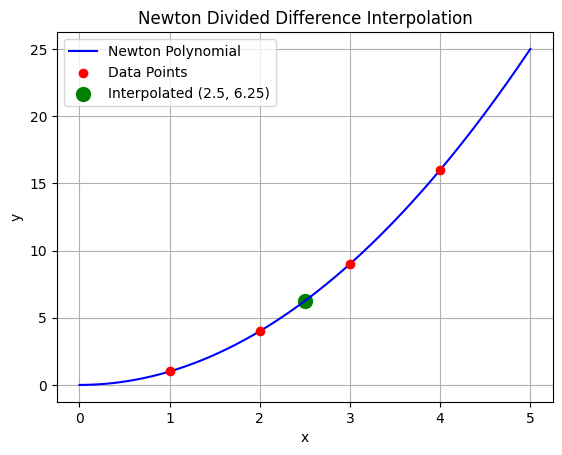

In [195]:
y_interp_val = plot_newton_divided_difference(
    x_vals, y_vals, poly, x_interp=x_interp_val
)

In [196]:
print(f"\nInterpolated value at x = {x_interp_val}: y = {y_interp_val:.2f}")


Interpolated value at x = 2.5: y = 6.25
